#STEP 1: Import libraries

In [18]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#STEP 2: Upload and unzip the dataset

In [19]:
from google.colab import files
import zipfile

uploaded = files.upload()                      # upload automobile.zip
with zipfile.ZipFile("automobile.zip", "r") as z:
    z.extractall("automobile_data")


Saving automobile.zip to automobile (1).zip


#STEP 3: Load the dataset

In [20]:
columns = [
    "symboling", "normalized_losses", "make", "fuel_type", "aspiration",
    "num_of_doors", "body_style", "drive_wheels", "engine_location",
    "wheel_base", "length", "width", "height", "curb_weight", "engine_type",
    "num_of_cylinders", "engine_size", "fuel_system", "bore", "stroke",
    "compression_ratio", "horsepower", "peak_rpm", "city_mpg",
    "highway_mpg", "price"
]

df = pd.read_csv("automobile_data/automobile/imports-85.data",
                 names=columns, na_values="?")

#STEP 4: First look at the data

In [21]:
print("----- HEAD -----")
print(df.head())

print("\n----- TAIL -----")
print(df.tail())

print("\n----- SHAPE (rows, columns) -----")
print(df.shape)

print("\n----- INFO -----")
df.info()

print("\n----- DESCRIBE (numeric) -----")
print(df.describe())

----- HEAD -----
   symboling  normalized_losses         make fuel_type aspiration  \
0          3                NaN  alfa-romero       gas        std   
1          3                NaN  alfa-romero       gas        std   
2          1                NaN  alfa-romero       gas        std   
3          2              164.0         audi       gas        std   
4          2              164.0         audi       gas        std   

  num_of_doors   body_style drive_wheels engine_location  wheel_base  ...  \
0          two  convertible          rwd           front        88.6  ...   
1          two  convertible          rwd           front        88.6  ...   
2          two    hatchback          rwd           front        94.5  ...   
3         four        sedan          fwd           front        99.8  ...   
4         four        sedan          4wd           front        99.4  ...   

   engine_size  fuel_system  bore  stroke compression_ratio horsepower  \
0          130         mpfi  3.

#STEP 5: Check missing values and duplicates  

In [22]:
missing = df.isnull().sum()
print("\n----- MISSING VALUES (only columns that have any) -----")
print(missing[missing > 0])

print("\nTotal duplicate rows:", df.duplicated().sum())


----- MISSING VALUES (only columns that have any) -----
normalized_losses    41
num_of_doors          2
bore                  4
stroke                4
horsepower            2
peak_rpm              2
price                 4
dtype: int64

Total duplicate rows: 0


#STEP 6: Clean the data


In [23]:
num_cols = ["normalized_losses", "bore", "stroke", "horsepower",
            "peak_rpm", "price"]
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df_clean = df.dropna(subset=["price"]).copy()
print("\nRows before cleaning:", len(df), "| after dropping missing price:", len(df_clean))


Rows before cleaning: 205 | after dropping missing price: 201


#Q1 - Which manufacturers appear most often?

In [24]:
make_counts = df_clean["make"].value_counts()
print("\n----- Q1: Top 10 manufacturers by number of cars -----")
print(make_counts.head(10))



----- Q1: Top 10 manufacturers by number of cars -----
make
toyota        32
nissan        18
mazda         17
mitsubishi    13
honda         13
subaru        12
volkswagen    12
volvo         11
peugot        11
dodge          9
Name: count, dtype: int64


#Q2 - Average, min and max price

In [25]:
price_arr = df_clean["price"].to_numpy()        # NumPy array

print("\n----- Q2: Price statistics (NumPy) -----")
print("Average price :", round(np.mean(price_arr), 2))
print("Minimum price :", np.min(price_arr))
print("Maximum price :", np.max(price_arr))
print("Median price  :", np.median(price_arr))
print("Std deviation :", round(np.std(price_arr), 2))


----- Q2: Price statistics (NumPy) -----
Average price : 13207.13
Minimum price : 5118.0
Maximum price : 45400.0
Median price  : 10295.0
Std deviation : 7927.27


#Q3 - Body style with highest average price

In [26]:
body_price = (df_clean.groupby("body_style")["price"]
              .mean()
              .sort_values(ascending=False)
              .round(2))
print("\n----- Q3: Average price by body style -----")
print(body_price)
print("Highest:", body_price.idxmax(), "->", body_price.max())


----- Q3: Average price by body style -----
body_style
hardtop        22208.50
convertible    21890.50
sedan          14459.76
wagon          12371.96
hatchback       9957.44
Name: price, dtype: float64
Highest: hardtop -> 22208.5


#Q4 - Average engine size by fuel type

In [27]:
engine_fuel = df_clean.groupby("fuel_type")["engine_size"].mean().round(2)
print("\n----- Q4: Average engine size by fuel type -----")
print(engine_fuel)


----- Q4: Average engine size by fuel type -----
fuel_type
diesel    135.7
gas       125.9
Name: engine_size, dtype: float64


#Q5: Missing values

In [28]:
# Keep only columns that actually have missing values
missing_counts = missing[missing > 0].sort_values(ascending=False)

print("Columns with missing values and their counts:")
print(missing_counts)

# Optional: show as a percentage of total rows too
missing_summary = pd.DataFrame({
    "missing_count": missing_counts,
    "missing_percent": (missing_counts / len(df) * 100).round(2)
})
print("\nSummary table:")
print(missing_summary)

print("\nTotal columns with missing values:", len(missing_counts))
print("Total missing cells:", int(df.isnull().sum().sum()))

Columns with missing values and their counts:
normalized_losses    41
bore                  4
stroke                4
price                 4
num_of_doors          2
horsepower            2
peak_rpm              2
dtype: int64

Summary table:
                   missing_count  missing_percent
normalized_losses             41            20.00
bore                           4             1.95
stroke                         4             1.95
price                          4             1.95
num_of_doors                   2             0.98
horsepower                     2             0.98
peak_rpm                       2             0.98

Total columns with missing values: 7
Total missing cells: 59


#Q6 - 10 most expensive cars

In [29]:
top10 = (df_clean.sort_values("price", ascending=False)
         [["make", "body_style", "fuel_type", "engine_size",
           "horsepower", "price"]]
         .head(10))
print("\n----- Q6: Top 10 most expensive cars -----")
print(top10.to_string(index=False))


----- Q6: Top 10 most expensive cars -----
         make  body_style fuel_type  engine_size  horsepower   price
mercedes-benz     hardtop       gas          304       184.0 45400.0
          bmw       sedan       gas          209       182.0 41315.0
mercedes-benz       sedan       gas          308       184.0 40960.0
      porsche convertible       gas          194       207.0 37028.0
          bmw       sedan       gas          209       182.0 36880.0
       jaguar       sedan       gas          326       262.0 36000.0
       jaguar       sedan       gas          258       176.0 35550.0
mercedes-benz convertible       gas          234       155.0 35056.0
mercedes-benz       sedan       gas          234       155.0 34184.0
      porsche     hardtop       gas          194       207.0 34028.0


#STEP 7: Extra - Pandas filtering + NumPy on horsepower

In [30]:
# Filtering example: cars costing more than 20,000
expensive = df_clean[df_clean["price"] > 20000]
print("\nCars priced above 20,000:", len(expensive))

# Filtering with multiple conditions: gas cars with horsepower > 150
powerful_gas = df_clean[(df_clean["fuel_type"] == "gas") &
                        (df_clean["horsepower"] > 150)]
print("Gas cars with horsepower > 150:", len(powerful_gas))

# NumPy statistics on horsepower (drop NaN first)
hp_arr = df_clean["horsepower"].dropna().to_numpy()
print("\nHorsepower  mean:", round(np.mean(hp_arr), 2),
      "| max:", np.max(hp_arr),
      "| 90th percentile:", np.percentile(hp_arr, 90))

# NumPy correlation between engine size and price
corr = np.corrcoef(df_clean["engine_size"].to_numpy(), price_arr)[0, 1]
print("Correlation (engine size vs price):", round(corr, 3))


Cars priced above 20,000: 25
Gas cars with horsepower > 150: 30

Horsepower  mean: 103.4 | max: 262.0 | 90th percentile: 160.0
Correlation (engine size vs price): 0.872


#STEP 8: Chart 1 - Manufacturer count

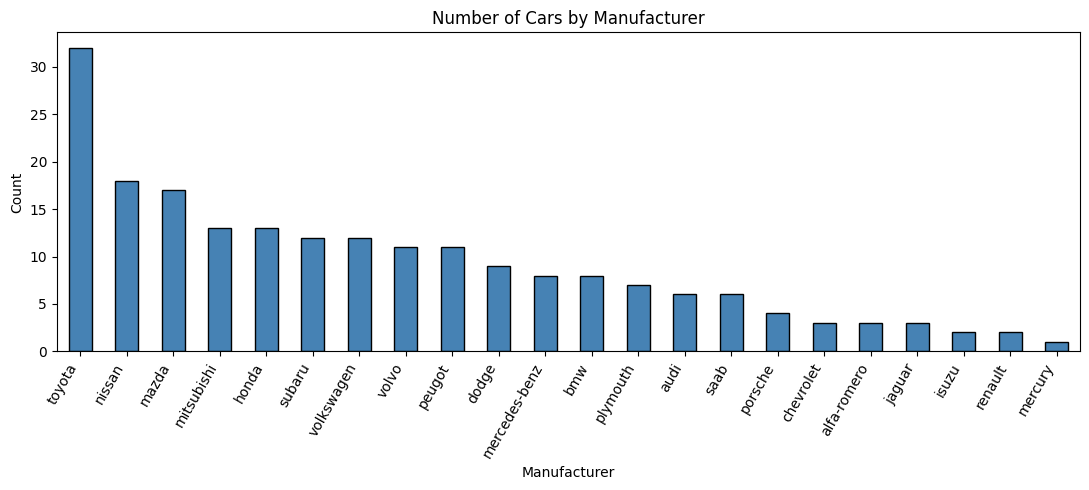

In [31]:
plt.figure(figsize=(11, 5))
make_counts.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Number of Cars by Manufacturer")
plt.xlabel("Manufacturer")
plt.ylabel("Count")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

# STEP 9: Chart 2 - Price histogram

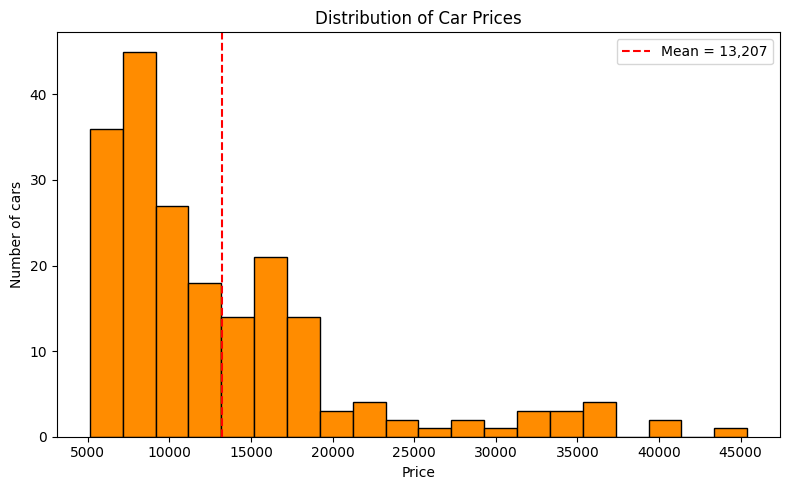

In [32]:
plt.figure(figsize=(8, 5))
plt.hist(price_arr, bins=20, color="darkorange", edgecolor="black")
plt.axvline(np.mean(price_arr), color="red", linestyle="--",
            label=f"Mean = {np.mean(price_arr):,.0f}")
plt.title("Distribution of Car Prices")
plt.xlabel("Price")
plt.ylabel("Number of cars")
plt.legend()
plt.tight_layout()
plt.show()

# STEP 10: Three observations

In [33]:
print("\n================ OBSERVATIONS ================")
print(f"1. '{make_counts.idxmax()}' is the most common make with "
      f"{make_counts.max()} cars; the top few makes dominate the dataset.")
print(f"2. '{body_price.idxmax()}' has the highest average price "
      f"({body_price.max():,.0f}), while prices overall range from "
      f"{np.min(price_arr):,.0f} to {np.max(price_arr):,.0f} "
      f"and are right-skewed (mean {np.mean(price_arr):,.0f} > median {np.median(price_arr):,.0f}).")
print(f"3. Engine size and price are strongly positively correlated "
      f"(r = {corr:.2f}); {engine_fuel.idxmax()} cars have the larger "
      f"average engine ({engine_fuel.max():.0f} vs {engine_fuel.min():.0f}).")


================ OBSERVATIONS ================
1. 'toyota' is the most common make with 32 cars; the top few makes dominate the dataset.
2. 'hardtop' has the highest average price (22,208), while prices overall range from 5,118 to 45,400 and are right-skewed (mean 13,207 > median 10,295).
3. Engine size and price are strongly positively correlated (r = 0.87); diesel cars have the larger average engine (136 vs 126).
